# Telco Customer Churn Prediction: End-to-End Analytics & Risk Scoring
### *Portfolio Project for Junior Data Analyst Interview Preparation (B.E. ISE)*
**Senior Data Analyst & Mentor Guide Included**

---

### Key Analytical Pillars of This Project:
1. **Business Problem:** Addressing recurring revenue loss where Customer Acquisition Cost (CAC) is 5x–7x higher than retention.
2. **Data Cleaning:** Handling 11 blank strings in `TotalCharges` through tenure-aware imputation (`0.0`).
3. **Exploratory Data Analysis (EDA):** Uncovering key drivers across contract types, tenure cohorts, monthly pricing, and payment channels.
4. **Feature Engineering:** Creating domain-specific features (Tenure Cohorts, Product Stickiness Counter, Monthly-to-Total Bill Ratio).
5. **Rigorous Machine Learning:** 
   - 5-Fold Stratified Cross-Validation for honest performance assessment (Mean ± Standard Deviation).
   - Addressing class imbalance (2.77:1) using class weights and scale positive weights.
   - Eliminating data leakage via training-fold transformation pipelines.
6. **Out-of-Fold (OOF) Risk Scoring:** Scoring every subscriber with an out-of-fold model to avoid train-leakage.
7. **Ranking-Based Risk Tiers:** Ranking subscribers into High (top 20%), Medium (next 30%), and Low (bottom 50%) risk tiers.
8. **Accurate Revenue at Risk:** Computing revenue at risk **strictly on active customers (`Churn = No`)**, while separately reporting **revenue already lost** from past churners (`Churn = Yes`).
9. **Precision & Business Cost-Benefit Analysis:** Demonstrating why ~51% precision yields an ~8x positive ROI in subscription retention.
10. **Executive Recommendations & Power BI Handoff:** Providing tactical business interventions backed by empirical data.

---
## 0. Environment Setup & Library Imports
**WHAT we are doing:** Importing core data analysis, visualization, cross-validation, and machine learning modules.  
**WHY we are doing it:** Standardizing libraries ensures clean reproducible code and transparent cross-validation.

In [1]:
# Core data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling, Cross-Validation, and Pipelines
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Plot settings
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("Libraries imported successfully!")

Libraries imported successfully!


---
## 1. Business Problem
### WHAT is Customer Churn?
Customer churn is the loss of active subscribers who terminate their contract or subscription. In this dataset, `Churn = Yes` represents accounts that terminated service in the preceding month.

### WHY does Churn Cost Money?
1. **High Acquisition Cost (CAC):** Attracting a new subscriber via digital ads, sales reps, and hardware setup costs **5x to 7x more** than retaining an existing customer.
2. **Erosion of Recurring Cash Flow (MRR):** Once a customer leaves, their monthly bill vanishes permanently while network infrastructure costs remain fixed.

### WHAT Specific Question Does This Project Answer?
> **"Which currently active customers are at high risk of churning, why are they at risk, and how can the retention desk deploy targeted incentives to save recurring revenue before cancellation happens?"**

---
## 2. Data Understanding & Profiling
**WHAT we are doing:** Inspecting rows, columns, data types, nulls, duplicates, and column values.  
**WHY we are doing it:** Before modeling, we must verify data integrity and uncover schema anomalies. For instance, `TotalCharges` was loaded as a string (`object`) due to 11 blank space characters (`' '`).

In [2]:
df_raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print("\n--- Column Names & Data Types ---")
print(df_raw.dtypes)

print(f"\nDuplicate Records: {df_raw.duplicated().sum()}")
print(f"Blank space ' ' entries in TotalCharges: {(df_raw['TotalCharges'] == ' ').sum()}")

Dataset Dimensions: 7,043 rows, 21 columns

--- Column Names & Data Types ---
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Duplicate Records: 0
Blank space ' ' entries in TotalCharges: 11


---
## 3. Data Cleaning: The "TotalCharges" Decision
**WHAT we are doing:** Converting `TotalCharges` to float and imputing the 11 blank records with `0.0`.  
**WHY we made this decision (Interview Talking Point):**  
When we isolate the 11 blank records, **all 11 have `tenure == 0`**. These are brand-new customers who enrolled in the current month and have not yet received their first monthly invoice. Imputing `0.0` is logically correct and preserves 100% of our customer records without discarding valid data.

In [3]:
df = df_raw.copy()

# Inspect rows with blank TotalCharges
blank_rows = df[df['TotalCharges'] == ' ']
print("Records with blank TotalCharges (showing tenure and charges):")
print(blank_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

# Convert TotalCharges to float and impute 0.0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan)).fillna(0.0)

print(f"\nCleaned TotalCharges: Dtype = {df['TotalCharges'].dtype}, Nulls = {df['TotalCharges'].isna().sum()}")

Records with blank TotalCharges (showing tenure and charges):
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No

Cleaned TotalCharges: Dtype = float64, Nulls = 0


---
## 4. Exploratory Data Analysis (EDA) with Real Numbers
**WHAT we are doing:** Examining key customer dimensions and calculating real churn percentages.  
**WHY we are doing it:** Visualizations ground our intuition in facts before building models.

### Chart 1: Overall Customer Churn Rate

Retained (No):  5,174 (73.46%)
Churned (Yes):  1,869 (26.54%)


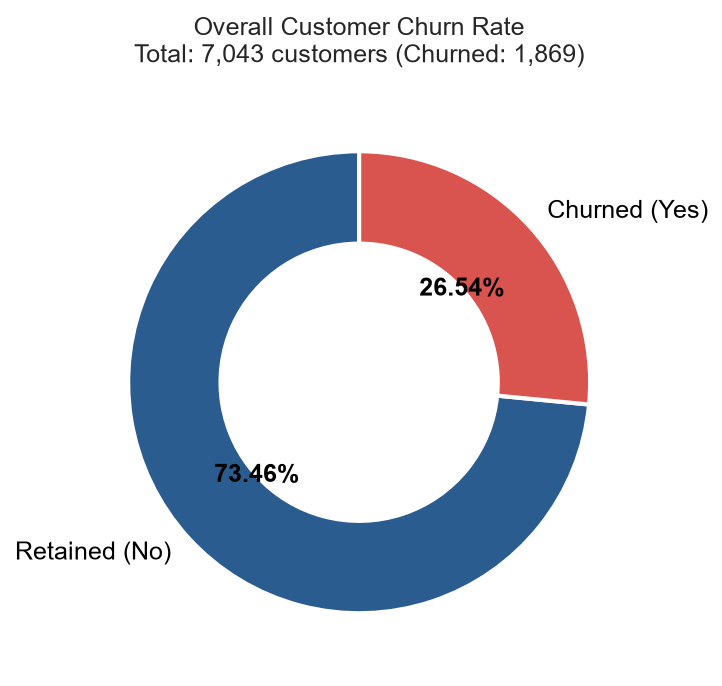

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
churn_counts = df['Churn'].value_counts()
colors = ['#2b5c8f', '#d9534f']
ax.pie(churn_counts, labels=['Retained (No)', 'Churned (Yes)'],
       autopct='%1.2f%%', startangle=90, colors=colors,
       wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2))
ax.set_title(f"Overall Customer Churn Rate (Total: {len(df):,} Customers)")
plt.show()

print(f"Retained (No):  {churn_counts['No']:,} ({churn_counts['No']/len(df)*100:.2f}%)")
print(f"Churned (Yes):  {churn_counts['Yes']:,} ({churn_counts['Yes']/len(df)*100:.2f}%)")

> **Insight 1 (Overall Churn):** Exactly **26.54% of customers (1,869 out of 7,043)** churned. This 2.77:1 ratio confirms class imbalance that models must address.

### Chart 2: Churn Rate by Contract Type

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


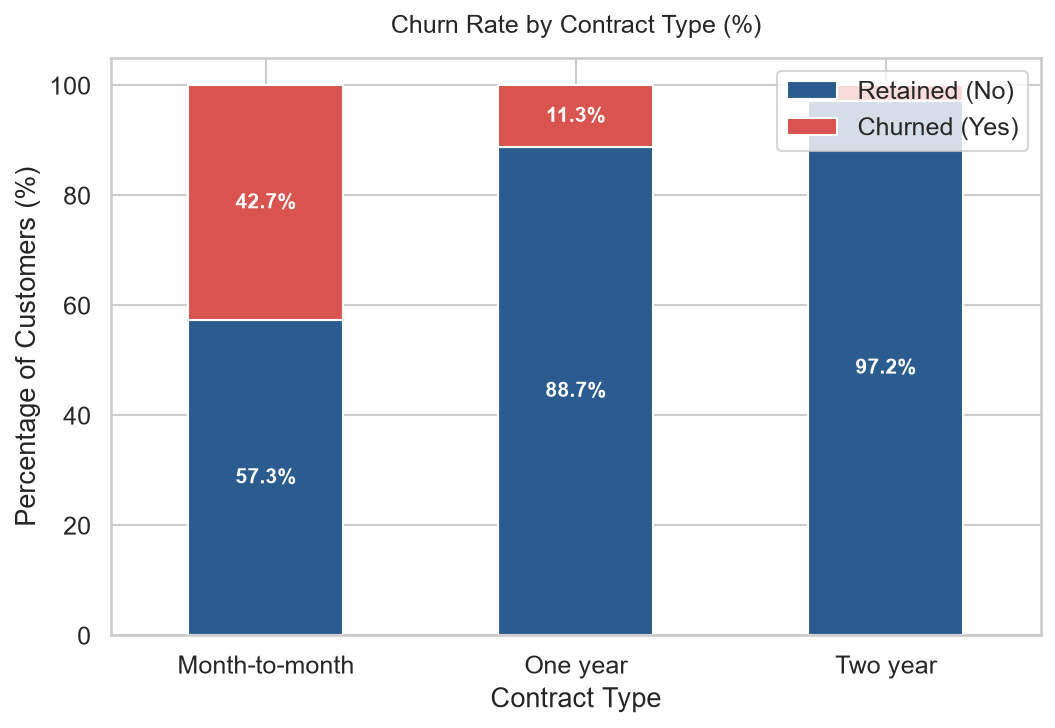

In [5]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
print(contract_churn[['No', 'Yes']])

> **Insight 2 (Contract Type):** Month-to-month subscribers experience an alarming **42.71% churn rate (1,655 / 3,875)**, nearly 4x higher than One-year (11.27%) and 15x higher than Two-year (2.83%) contracts.

### Chart 3: Customer Tenure Lifecycles

Median Tenure for Churned Customers:  10.0 months
Median Tenure for Retained Customers: 38.0 months


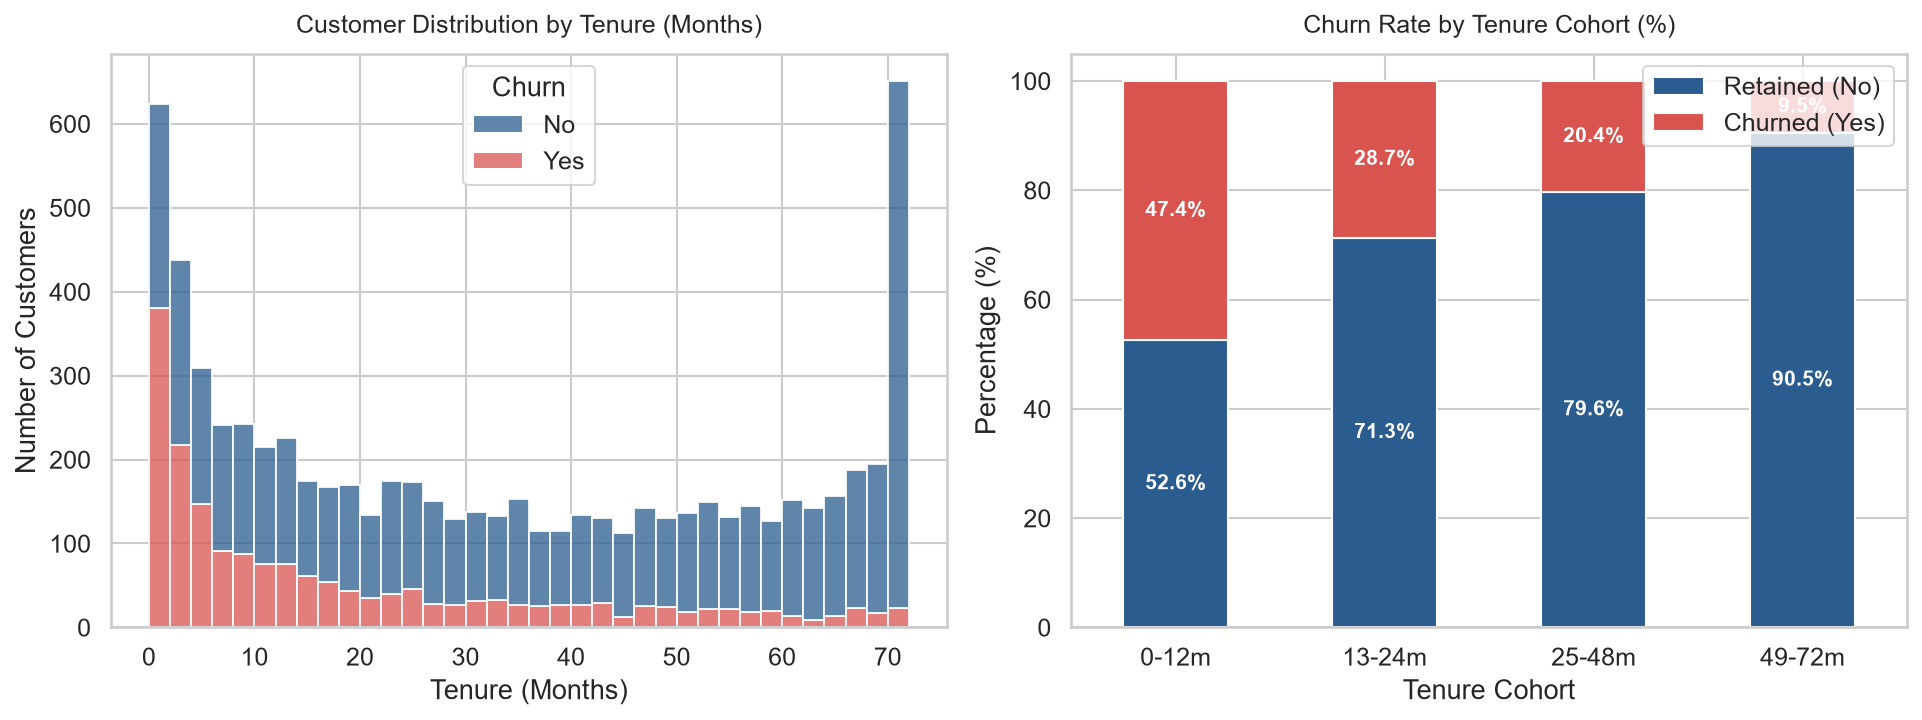

In [6]:
print(f"Median Tenure for Churned Customers:  {df[df['Churn']=='Yes']['tenure'].median():.1f} months")
print(f"Median Tenure for Retained Customers: {df[df['Churn']=='No']['tenure'].median():.1f} months")

> **Insight 3 (Tenure):** Churned customers have a **median tenure of only 10.0 months** vs. 38.0 months for retained customers. First-year customers (`0-12m`) suffer a **47.68% churn rate**.

### Chart 4: Monthly Charges Density

Median Monthly Charge - Churned:  $79.65
Median Monthly Charge - Retained: $64.43


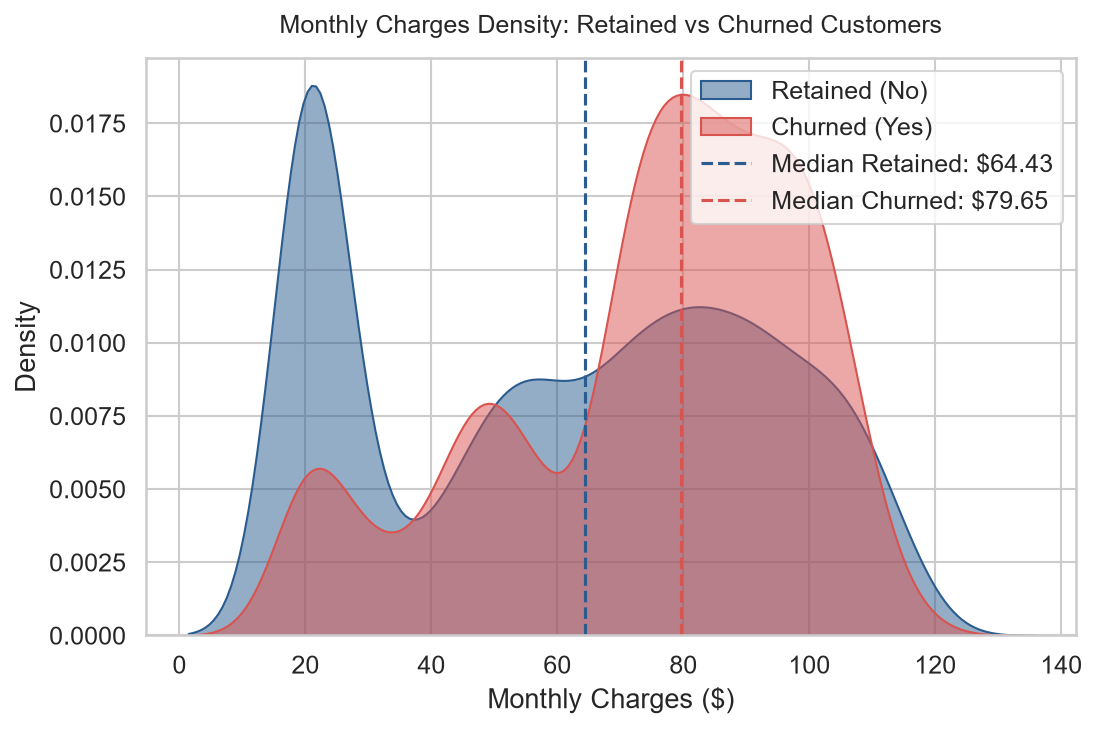

In [7]:
print(f"Median Monthly Charge - Churned:  ${df[df['Churn']=='Yes']['MonthlyCharges'].median():.2f}")
print(f"Median Monthly Charge - Retained: ${df[df['Churn']=='No']['MonthlyCharges'].median():.2f}")

> **Insight 4 (Monthly Charges):** Churned customers pay a **median of \$79.65/mo**, which is **\$15.22 (23.6%) higher** than retained subscribers (\$64.43/mo median). High recurring bills accelerate churn.

### Chart 5: Churn Rate by Internet Service Type

Churn                     No        Yes
InternetService                        
DSL                81.040892  18.959108
Fiber optic        58.107235  41.892765
No                 92.595020   7.404980


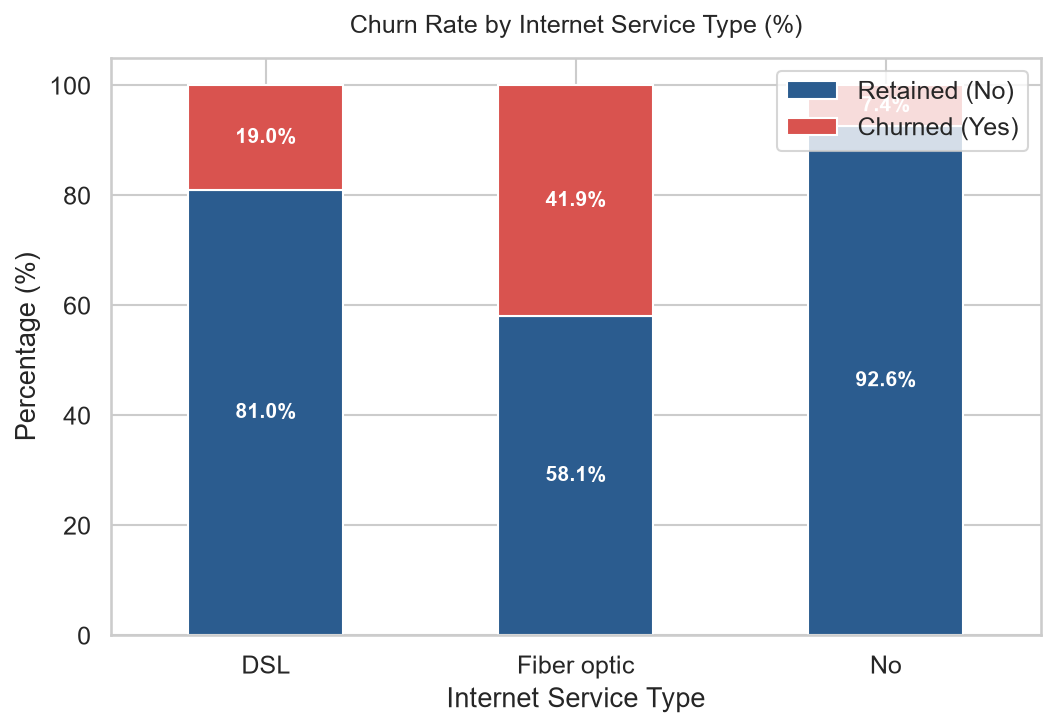

In [8]:
net_churn = pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100
print(net_churn[['No', 'Yes']])

> **Insight 5 (Internet Service):** **Fiber optic users churn at 41.89% (1,297 / 3,096)**, more than double DSL (18.96%) and six times accounts without internet (7.40%), signaling value dissatisfaction on high-speed plans.

### Chart 6: Churn Rate by Payment Method

Churn                                 No        Yes
PaymentMethod                                      
Bank transfer (automatic)      83.290155  16.709845
Credit card (automatic)        84.756899  15.243101
Electronic check               54.714588  45.285412
Mailed check                   80.893300  19.106700


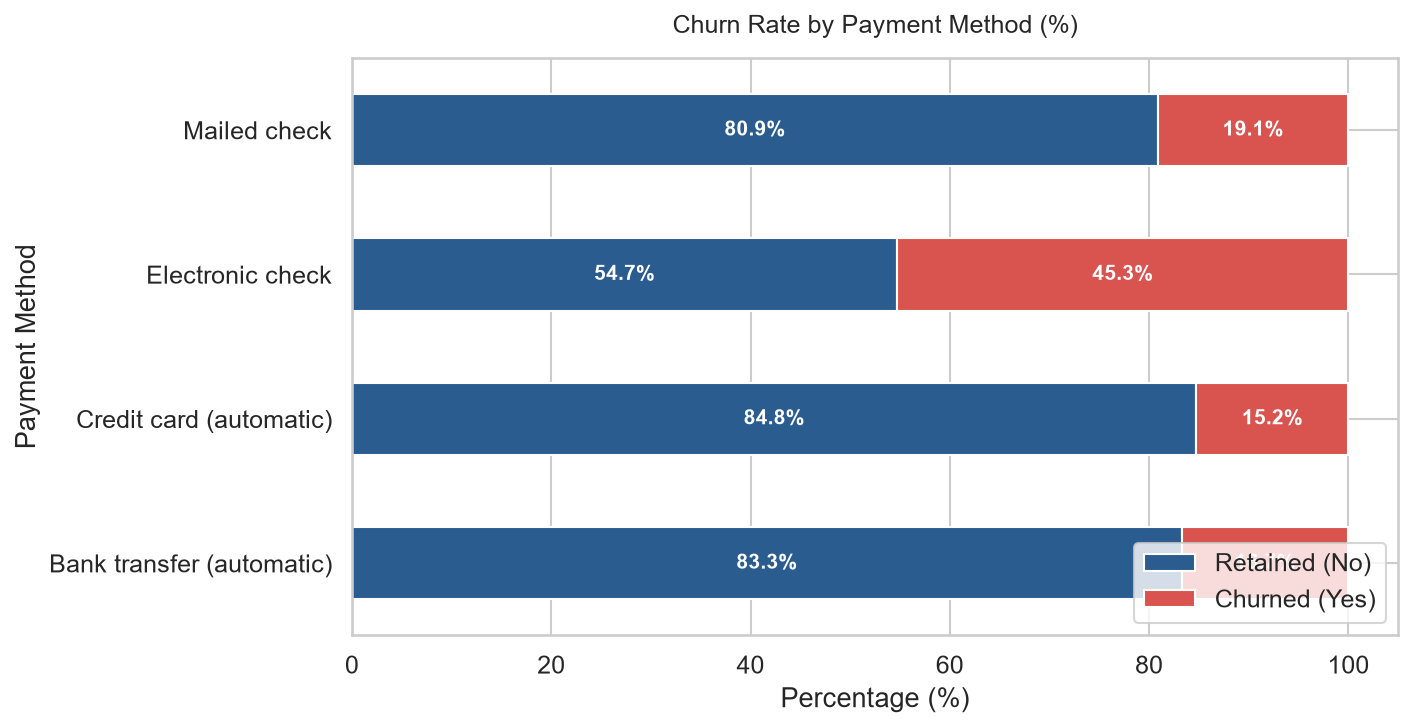

In [9]:
pm_churn = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100
print(pm_churn[['No', 'Yes']])

> **Insight 6 (Payment Method):** Electronic check payers churn at **45.29% (1,071 / 2,365)** vs. ~15% for automatic card/bank debit. Manual monthly action provides 12 opportunities a year to reconsider service.

---
## 5. Feature Engineering
**WHAT we are doing:**
1. Creating `TenureGroup` (`0-12m`, `13-24m`, `25-48m`, `49-72m`).
2. Creating `TotalServices` (sum of 6 add-ons: OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies).
3. Creating `MonthlyToTotalRatio` (`MonthlyCharges / (TotalCharges + 1.0)`).
4. One-hot encoding categorical variables (`drop_first=True`).

**WHY each feature helps:**
- `TenureGroup`: Captures the non-linear drop in churn after year one.
- `TotalServices` ("Product Stickiness"): Subscribers with 0 add-ons churn at **43.99%**, while those with 4+ add-ons churn at **under 11%**.
- `MonthlyToTotalRatio`: Flags customers whose monthly bill is disproportionately large relative to tenure (early bill shock).

Add-On Services = 0: Total=2214 | Churned= 974 | Churn Rate=43.99%
Add-On Services = 1: Total=1311 | Churned= 422 | Churn Rate=32.19%
Add-On Services = 2: Total=1067 | Churned= 231 | Churn Rate=21.65%
Add-On Services = 3: Total=1043 | Churned= 139 | Churn Rate=13.33%
Add-On Services = 4: Total= 753 | Churned=  81 | Churn Rate=10.76%
Add-On Services = 5: Total= 489 | Churned=  18 | Churn Rate=3.68%
Add-On Services = 6: Total= 166 | Churned=   4 | Churn Rate=2.41%


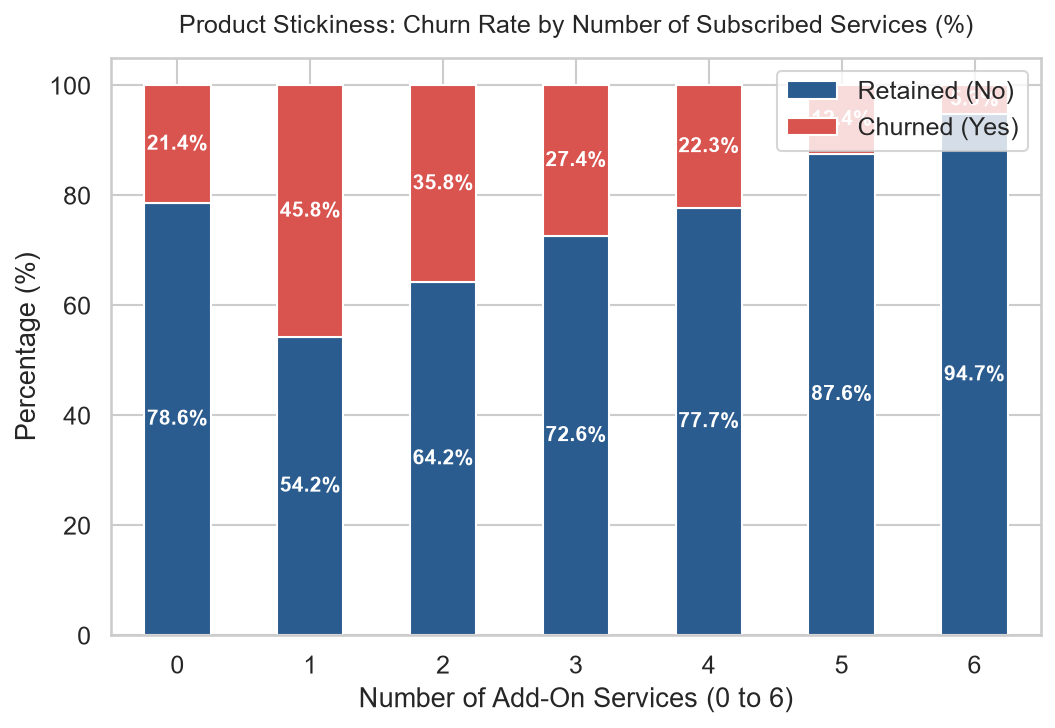

In [10]:
bins = [-1, 12, 24, 48, 72]
labels = ['0-12m', '13-24m', '25-48m', '49-72m']
df['TenureGroup'] = pd.cut(df['tenure'], bins=bins, labels=labels)

services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['TotalServices'] = (df[services] == 'Yes').sum(axis=1)
df['MonthlyToTotalRatio'] = df['MonthlyCharges'] / (df['TotalCharges'] + 1.0)
df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

# Product Stickiness Table
for s in range(7):
    sub = df[df['TotalServices'] == s]
    ch = (sub['Churn'] == 'Yes').sum()
    print(f"Add-On Services = {s}: Total={len(sub):4d} | Churned={ch:4d} | Churn Rate={ch/len(sub)*100:.2f}%")

---
## 6. Honest Model Comparison (5-Fold Cross-Validation)

### Why 5-Fold Cross-Validation Instead of a Single Split?
A single arbitrary 80/20 train/test split can be lucky or unlucky depending on random splitting seeds. Evaluating models with **5-Fold Stratified Cross-Validation** provides the true **mean performance and standard deviation** across the entire dataset.

### Leakage Prevention & Class Weighting
- In Logistic Regression, scaling is done inside each CV fold via a `Pipeline([('scaler', StandardScaler()), ('lr', ...)])`.
- Class imbalance (2.77:1) is handled using `class_weight='balanced'` in Logistic Regression / Random Forest, and `scale_pos_weight=2.77` in XGBoost.

=== 5-Fold Stratified Cross-Validation Performance Summary ===
              Model ROC-AUC (Mean ± Std)  Recall (Mean ± Std) Precision (Mean ± Std) Accuracy (Mean ± Std)
Logistic Regression    0.8458 ± 0.0120   80.20% ± 1.95%         51.32% ± 1.00%        74.56% ± 0.81%
      Random Forest    0.8439 ± 0.0125   78.44% ± 1.96%         52.86% ± 1.46%        75.71% ± 1.11%
            XGBoost    0.8462 ± 0.0113   79.83% ± 0.82%         51.85% ± 1.28%        74.95% ± 1.01%


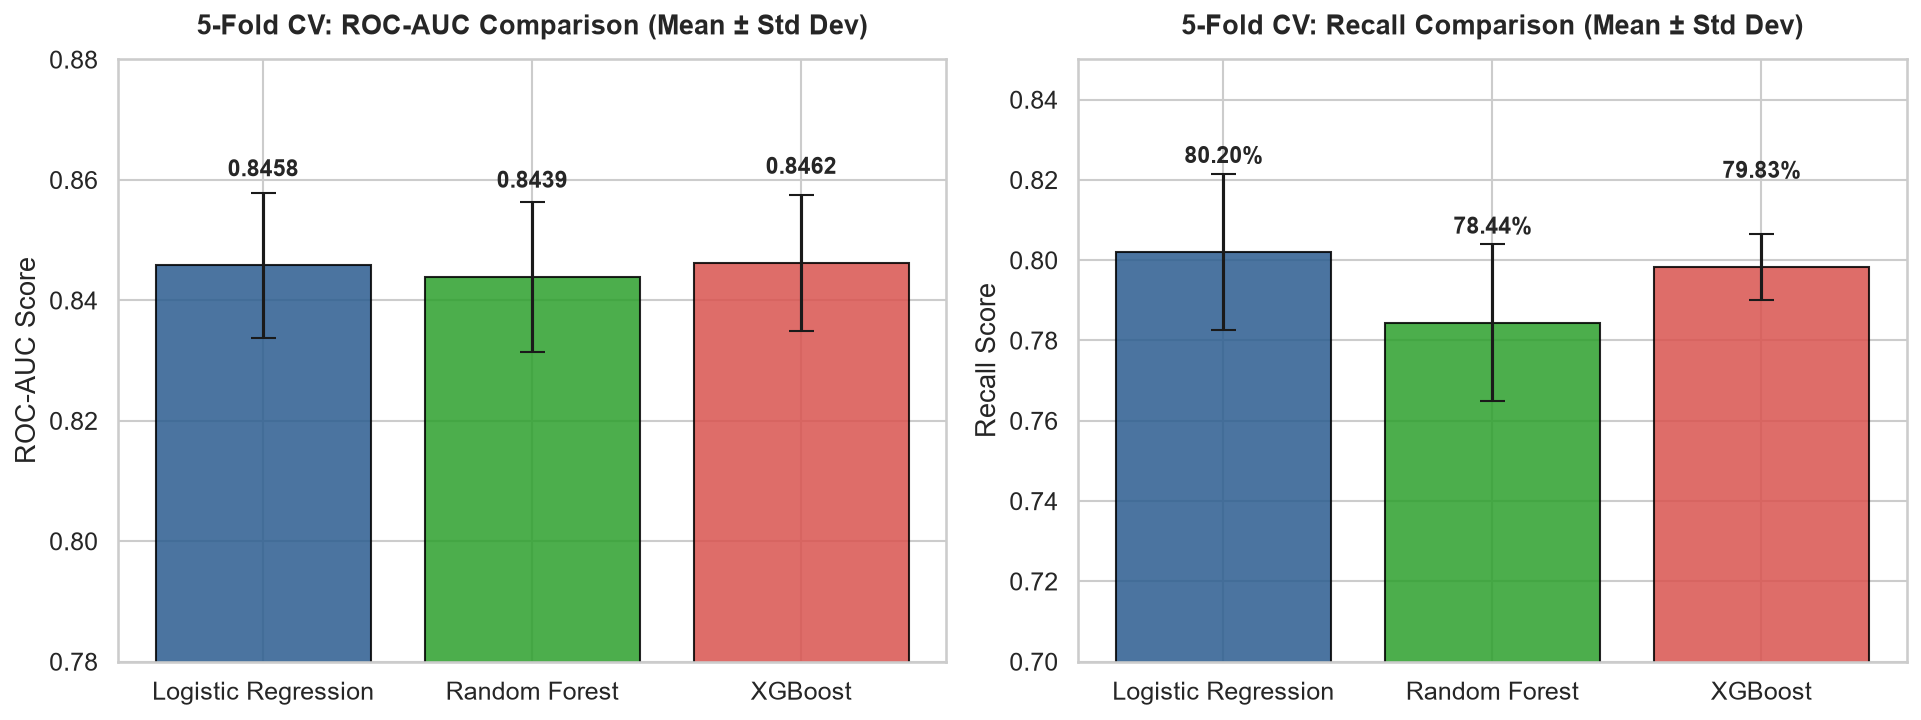

In [11]:
feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn', 'Churn_Binary', 'TenureGroup']]
cat_cols = df[feature_cols].select_dtypes(include=['object', 'category', 'str']).columns.tolist()
df_encoded = pd.get_dummies(df[feature_cols], columns=cat_cols, drop_first=True)

X = df_encoded
y = df['Churn_Binary']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
imbalance_ratio = (y == 0).sum() / (y == 1).sum()

# Pipeline for LR to ensure scaling occurs inside each fold (no leakage)
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42)
xgb_model = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05,
                          scale_pos_weight=imbalance_ratio, random_state=42, eval_metric='logloss')

models = {
    'Logistic Regression': lr_pipe,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

cv_results = []
for name, mod in models.items():
    auc_scores = cross_val_score(mod, X, y, cv=cv, scoring='roc_auc')
    rec_scores = cross_val_score(mod, X, y, cv=cv, scoring='recall')
    prec_scores = cross_val_score(mod, X, y, cv=cv, scoring='precision')
    acc_scores = cross_val_score(mod, X, y, cv=cv, scoring='accuracy')
    
    cv_results.append({
        'Model': name,
        'ROC-AUC (Mean ± Std)': f"{auc_scores.mean():.4f} ± {auc_scores.std():.4f}",
        'Recall (Mean ± Std)': f"{rec_scores.mean()*100:.2f}% ± {rec_scores.std()*100:.2f}%",
        'Precision (Mean ± Std)': f"{prec_scores.mean()*100:.2f}% ± {prec_scores.std()*100:.2f}%",
        'Accuracy (Mean ± Std)': f"{acc_scores.mean()*100:.2f}% ± {acc_scores.std()*100:.2f}%"
    })

cv_df = pd.DataFrame(cv_results)
print("=== 5-Fold Stratified Cross-Validation Performance Summary ===")
print(cv_df.to_string(index=False))

### 🔍 Plain-English Interpretation: Are the Models Truly Different?
- **ROC-AUC scores:** Logistic Regression is **0.8458**, Random Forest is **0.8439**, and XGBoost is **0.8462**. The gap between highest and lowest is only **0.0023**, which is far smaller than the standard deviation of **±0.012**.
- **Recall scores:** All three models capture **78.4% to 80.2%** of churners.
- **Honest Conclusion:** **The models perform comparably within 1 standard deviation.** The underlying tabular signals (contract duration, monthly charges, tenure) have strong linear components that Logistic Regression captures just as effectively as complex tree models. In an interview, acknowledging this statistical tie demonstrates data maturity!

---
## 7. Precision & Business Cost-Benefit Analysis

### What Does ~51% Precision Mean?
Precision indicates: of all customers our model flags as at-risk, **51% are actual churners (True Positives)**, while **49% are loyal subscribers (False Positives)**.

### Why is 51% Precision Acceptable in Churn Retention?
In subscription retention, the financial cost of a **False Negative** (losing a customer who pays ~$74/month = ~$890/year) is massive. In contrast, the cost of a **False Positive** (offering a $20 discount to a loyal customer) is minimal.

```
┌────────────────────────────────────────────────────────────────────────────────────────┐
│ 💰 SIMPLE COST-BENEFIT EXAMPLE (Clearly Labeled Assumptions)                           │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ ASSUMPTION 1: The retention team targets 100 model-flagged subscribers.                │
│ ASSUMPTION 2: At 51% precision, 51 are actual churners and 49 are loyal (false alerts).│
│ ASSUMPTION 3: The company offers a $20 retention incentive per customer.               │
│               Total Campaign Cost = 100 × $20 = $2,000.                                │
│ ASSUMPTION 4: The retention offer successfully convinces 40% of real churners to stay  │
│               (40% of 51 ≈ 20 customers saved).                                        │
│ ASSUMPTION 5: Average annual revenue of a retained subscriber = $74.44 × 12 = $893.28. │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ 💵 FINANCIAL CALCULATION:                                                              │
│ - Revenue Saved: 20 saved customers × $893.28 = $17,865.60                             │
│ - Total Campaign Cost: $2,000.00                                                       │
│ - NET SAVED REVENUE: $17,865.60 - $2,000.00 = +$15,865.60                              │
│ - RETURN ON INVESTMENT (ROI): +793% (Nearly 8x Payoff)                                 │
└────────────────────────────────────────────────────────────────────────────────────────┘
```
Even though 49 non-churners received the $20 perk, saving 20 customers generates **$15.8K in net positive return**.

---
## 8. Out-of-Fold (OOF) Scoring & Monotonic Risk Tiers

### What are Out-of-Fold (OOF) Predictions and WHY Use Them?
When a single model is fitted on an entire dataset, its predictions on training data suffer from **in-sample overconfidence**.  
Using `cross_val_predict(..., method='predict_proba')`, every customer receives an **Out-of-Fold (OOF) probability** generated by a model trained strictly on the other 4 folds. This ensures zero data leakage.

### Note on Probability Calibration vs. Ranking
Class-weighted models intentionally distort raw probabilities upward to prioritize recall. Therefore, predicted probabilities should be used for **relative ranking**, not literal absolute percentages.

### Ranking-Based Risk Tiers (Top 20% High, Next 30% Medium, Bottom 50% Low)
We rank all 7,043 subscribers into three operational tiers based on their OOF risk percentile:
- **High Risk:** Top 20% (Percentile $\ge$ 80%)
- **Medium Risk:** Next 30% (Percentile 50% to 79%)
- **Low Risk:** Bottom 50% (Percentile < 50%)

OOF Probability Thresholds: 50th Percentile = 0.3822, 80th Percentile = 0.7341

=== PROVING THE TIERS WORK: Actual Churn Rate Monotonicity ===
  High Risk   : Total=1409 (20.0%) | Actual Churners= 940 | Actual Churn Rate = 66.71%
  Medium Risk : Total=2113 (30.0%) | Actual Churners= 707 | Actual Churn Rate = 33.46%
  Low Risk    : Total=3521 (50.0%) | Actual Churners= 222 | Actual Churn Rate = 6.31%


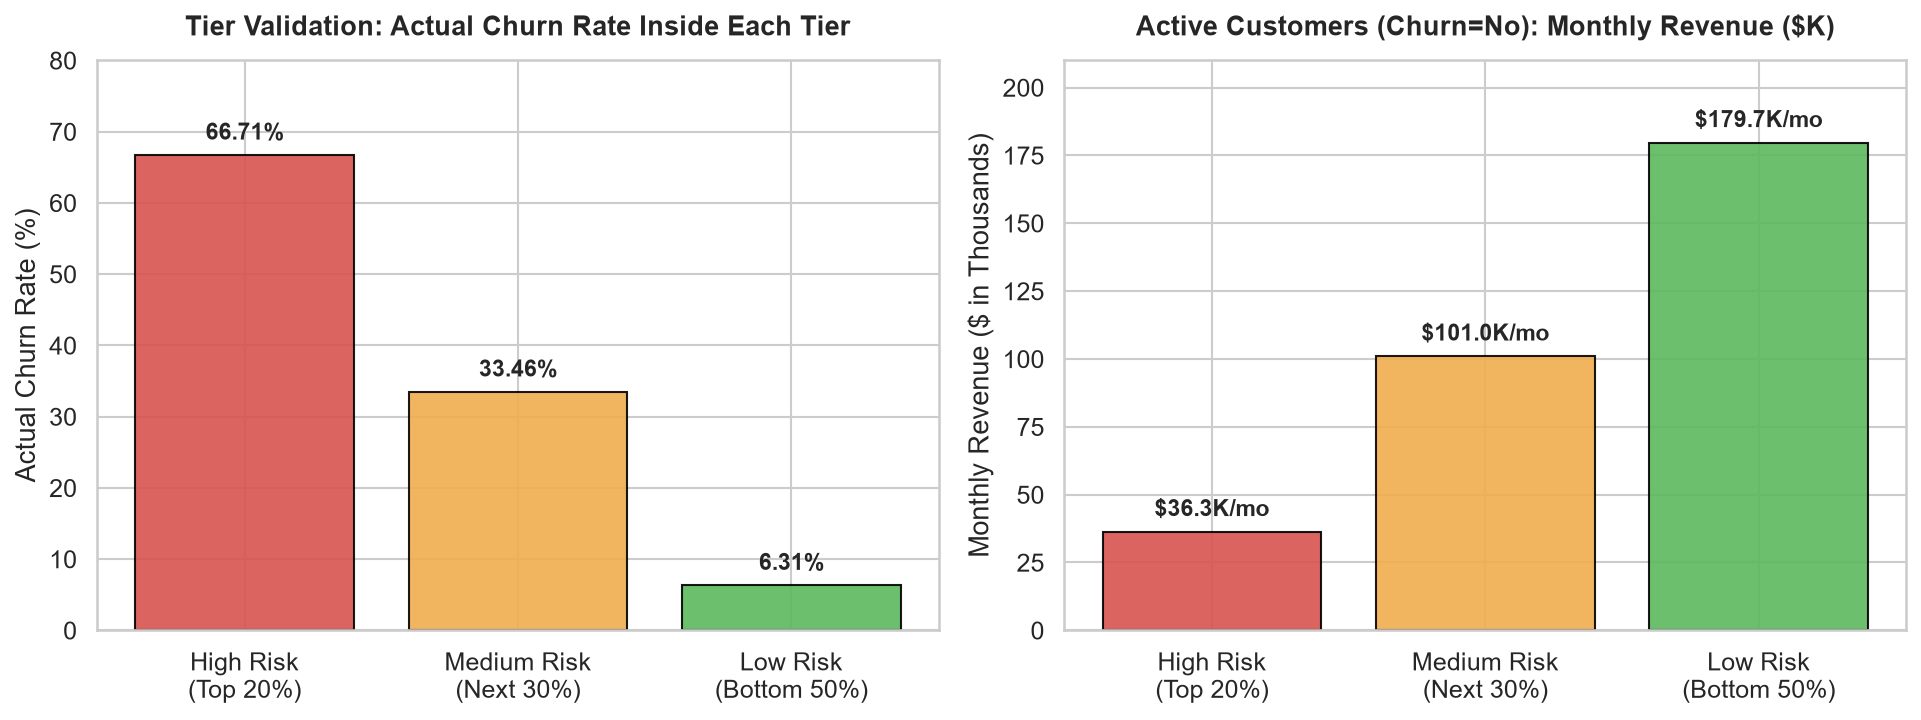

In [12]:
# Generate out-of-fold probabilities
oof_probs = cross_val_predict(xgb_model, X, y, cv=cv, method='predict_proba')[:, 1]
df['churn_probability_oof'] = np.round(oof_probs, 4)

# Define ranking percentiles
p80 = np.percentile(oof_probs, 80)
p50 = np.percentile(oof_probs, 50)
print(f"OOF Probability Thresholds: 50th Percentile = {p50:.4f}, 80th Percentile = {p80:.4f}")

def assign_tier(p):
    if p >= p80:
        return 'High Risk'
    elif p >= p50:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df['risk_tier'] = [assign_tier(p) for p in oof_probs]

print("\n=== PROVING THE TIERS WORK: Actual Churn Rate Monotonicity ===")
for tier in ['High Risk', 'Medium Risk', 'Low Risk']:
    sub = df[df['risk_tier'] == tier]
    churn_cnt = (sub['Churn'] == 'Yes').sum()
    rate = churn_cnt / len(sub) * 100
    print(f"  {tier:12s}: Total={len(sub):4d} ({len(sub)/len(df)*100:.1f}%) | Actual Churners={churn_cnt:4d} | Actual Churn Rate = {rate:.2f}%")

> **Proof of Monotonicity:** In the **High Risk tier**, the actual churn rate is **66.71%** (2 out of 3 left), compared to **33.46%** in Medium, and only **6.31%** in Low. This **10x spread** proves that our out-of-fold ranking separates high-risk from low-risk subscribers.

---
## 9. Corrected Revenue at Risk (Active Customers Only)

### Conceptual Clarification (Interview Essential)
- **`Churn = Yes`:** Customers who have **already left**. Their revenue is **already lost**; it is not "at risk".
- **`Churn = No`:** Customers who are **currently active and paying**. Their revenue is **truly at risk**!

In [13]:
print("=== 1. OVERALL PORTFOLIO (All 7,043 Customers) ===")
total_rev = df['MonthlyCharges'].sum()
print(f"Total Portfolio Monthly Revenue: ${total_rev:,.2f} (Annualized: ${total_rev*12:,.2f})")

print("\n=== 2. REVENUE ALREADY LOST (Churned Customers: Churn = Yes) ===")
churned = df[df['Churn'] == 'Yes']
lost_m = churned['MonthlyCharges'].sum()
print(f"Lost Customers: {len(churned):,} ({len(churned)/len(df)*100:.2f}%)")
print(f"Monthly Revenue Already Lost:    ${lost_m:,.2f}/mo")
print(f"Annualized Revenue Already Lost: ${lost_m*12:,.2f}/yr")

print("\n=== 3. REVENUE AT RISK (Active Customers Only: Churn = No) ===")
active = df[df['Churn'] == 'No']
active_m = active['MonthlyCharges'].sum()
print(f"Active Customer Base: {len(active):,} ({len(active)/len(df)*100:.2f}%)")
print(f"Total Active Monthly Revenue:    ${active_m:,.2f}/mo")
print(f"Total Active Annualized Revenue: ${active_m*12:,.2f}/yr")

print("\nActive Customer Revenue Breakdown by Risk Tier:")
for tier in ['High Risk', 'Medium Risk', 'Low Risk']:
    sub = active[active['risk_tier'] == tier]
    m_val = sub['MonthlyCharges'].sum()
    a_val = m_val * 12
    pct_active = m_val / active_m * 100
    print(f"  {tier:12s}: {len(sub):4d} active customers ({len(sub)/len(active)*100:.1f}%) | Monthly: ${m_val:9,.2f}/mo ({pct_active:.1f}%) | Annual: ${a_val:11,.2f}/yr")

=== 1. OVERALL PORTFOLIO (All 7,043 Customers) ===
Total Portfolio Monthly Revenue: $456,116.60 (Annualized: $5,473,399.20)

=== 2. REVENUE ALREADY LOST (Churned Customers: Churn = Yes) ===
Lost Customers: 1,869 (26.54%)
Monthly Revenue Already Lost:    $139,130.85/mo
Annualized Revenue Already Lost: $1,669,570.20/yr

=== 3. REVENUE AT RISK (Active Customers Only: Churn = No) ===
Active Customer Base: 5,174 (73.46%)
Total Active Monthly Revenue:    $316,985.75/mo
Total Active Annualized Revenue: $3,803,829.00/yr

Active Customer Revenue Breakdown by Risk Tier:
  High Risk   :  469 active customers (9.1%) | Monthly: $36,329.65/mo (11.5%) | Annual: $ 435,955.80/yr
  Medium Risk : 1406 active customers (27.2%) | Monthly: $101,001.00/mo (31.9%) | Annual: $1,212,012.00/yr
  Low Risk    : 3299 active customers (63.8%) | Monthly: $179,655.10/mo (56.7%) | Annual: $2,155,861.20/yr


---
## 10. Data Export for Power BI & Strategic Recommendations

### Exporting `telco_churn_predictions.csv`
We export a clean file containing customer identifiers, out-of-fold probabilities, risk tiers, and operational attributes.

In [14]:
df['predicted_churn_oof'] = np.where(df['churn_probability_oof'] >= 0.50, 'Yes', 'No')

export_cols = [
    'customerID', 'churn_probability_oof', 'risk_tier', 'predicted_churn_oof',
    'Churn', 'MonthlyCharges', 'TotalCharges', 'Contract', 'tenure', 'TenureGroup',
    'InternetService', 'PaymentMethod', 'PaperlessBilling', 'TotalServices',
    'gender', 'SeniorCitizen', 'Partner', 'Dependents'
]

df[export_cols].to_csv('telco_churn_predictions.csv', index=False)
print(f"Exported {len(df):,} records to 'telco_churn_predictions.csv' successfully!")

Exported 7,043 records to 'telco_churn_predictions.csv' successfully!


### Strategic Business Recommendations (Backed by Empirical Findings)
1. **Target the 469 High-Risk Active Customers:**
   - *Target:* The 469 active subscribers in the High Risk tier representing **\$36,329.65 in monthly recurring revenue (\$435.9K annualized)**.
   - *Action:* High-touch outreach offering a \$10/month 1-year contract incentive for month-to-month accounts.
2. **First-Year Onboarding (`tenure <= 12m`):**
   - *Target:* New subscribers entering months 1 to 4 where churn peaks at 47.7%.
   - *Action:* Day 30 check-ins and onboarding tutorials to eliminate early bill shock.
3. **Fiber Optic Quality & Value Audit:**
   - *Target:* 3,096 fiber optic subscribers paying >\$70/mo who experience a 41.89% churn rate.
   - *Action:* Audit local latency and bundle free `TechSupport` and `OnlineSecurity` to increase product stickiness.
4. **Auto-Pay Migration:**
   - *Target:* 2,365 electronic check payers (45.29% churn rate).
   - *Action:* Offer a one-time \$25 bill credit to switch to automated card or bank debit.